# Anomaly detection with anomalib

[anomalib](https://github.com/open-edge-platform/anomalib) is a library of anomaly detection models for images.
This notebook uses it for visual inspection of manufactured parts, on the *metal nut* category of the
[MVTec AD](https://www.mvtec.com/company/research/datasets/mvtec-ad) dataset: the model is trained on photos of
good metal nuts only, then has to find defective ones (bent, scratched, flipped, or with a color spot),
and *where* the defect is. It's the same setup as the assignment, on real images.

The model is **PatchCore** ([Roth et al. 2022](https://arxiv.org/abs/2106.08265)). It does not train a network.
Instead, it passes the good training images through a CNN pre-trained on ImageNet, and stores the features of
their image patches in a *memory bank*. A patch of a new image is anomalous if it is far from every patch in the
memory bank; the anomaly score of the image is the largest of these distances.

MVTec AD: Paul Bergmann, Michael Fauser, David Sattlegger, and Carsten Steger, "A Comprehensive Real-World Dataset
for Unsupervised Anomaly Detection", CVPR 2019. Licensed under
[CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) (non-commercial use).

In [1]:
import os
import logging
import warnings

# Hide the progress bar of PatchCore's memory bank sampling.
os.environ['TQDM_DISABLE'] = '1'
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
%config InlineBackend.figure_format = 'retina'

import lightning as L
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore

# Hide informational messages of anomalib and PyTorch Lightning
# (after importing them, because importing them sets up their loggers).
for name in list(logging.root.manager.loggerDict):
    if name.startswith(('lightning', 'anomalib')):
        logging.getLogger(name).setLevel(logging.ERROR)

## Dataset

The metal nut images are downloaded from the course S3 bucket (160MB) and extracted into the folder structure
of MVTec AD, which anomalib's `MVTecAD` dataset reads:

- `train/good`: 220 photos of good metal nuts, the only training data
- `test/<defect>`: photos of good and defective metal nuts
- `ground_truth/<defect>`: for each defective test image, a mask of the defect's pixels

In [2]:
import boto3
import tarfile

root = Path('anomalib_dataset')
root.mkdir(exist_ok=True)

archive = root / 'metal_nut.tar.xz'
if not archive.exists():
    boto3.client('s3').download_file('danylo-ucla', 'mvtec-ad/metal_nut.tar.xz', str(archive))

if not (root / 'metal_nut').exists():
    with tarfile.open(archive) as f:
        f.extractall(root, filter='data')

{
    f'{split}/{folder.name}': len(list(folder.glob('*.png')))
    for split in ['train', 'test']
    for folder in sorted((root / 'metal_nut' / split).iterdir())
}

{'train/good': 220,
 'test/bent': 25,
 'test/color': 22,
 'test/flip': 23,
 'test/good': 22,
 'test/scratch': 23}

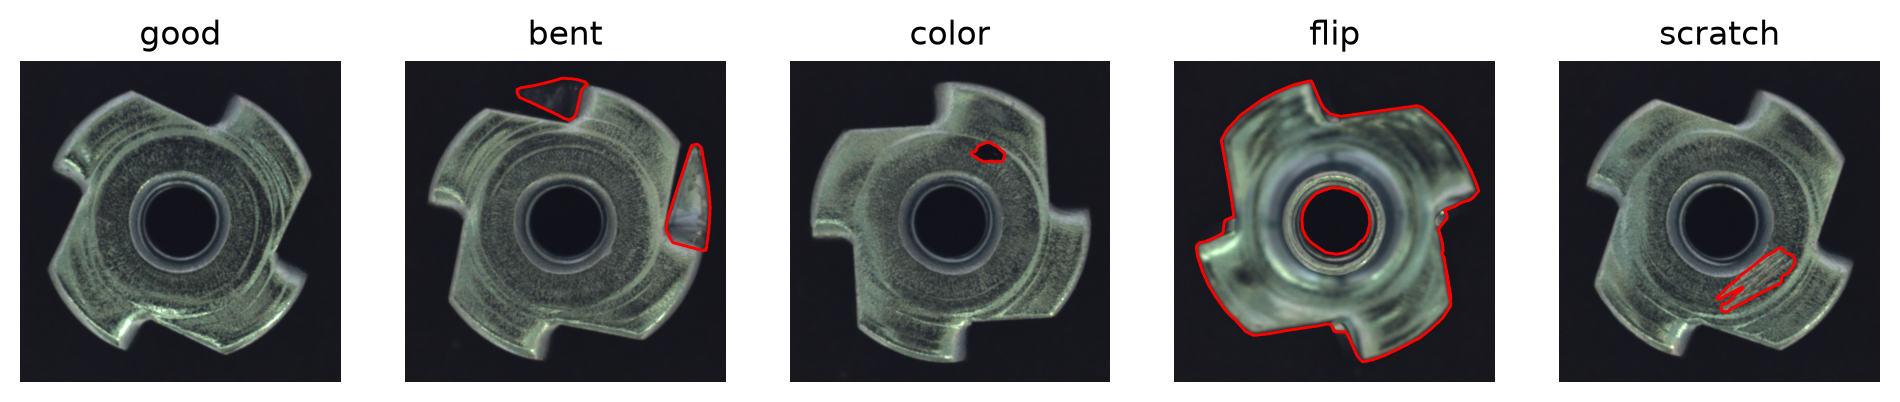

In [3]:
# A good metal nut, and an example of each defect with its ground truth mask (outlined in red).
defects = ['good', 'bent', 'color', 'flip', 'scratch']

fig, axes = plt.subplots(1, len(defects), figsize=(len(defects) * 2.4, 2.6))
for ax, defect in zip(axes, defects):
    image = Image.open(root / 'metal_nut' / 'test' / defect / '000.png')
    ax.imshow(image)
    if defect != 'good':
        mask = np.asarray(Image.open(root / 'metal_nut' / 'ground_truth' / defect / '000_mask.png'))
        ax.contour(mask > 0, colors='red', linewidths=1)
    ax.set_title(defect)
    ax.axis('off')
plt.show()

## Model

anomalib models are PyTorch Lightning modules, trained by anomalib's `Engine` (a Lightning `Trainer`).
Other models can be swapped in with the same code, e.g. `Padim`, `EfficientAd`, `Fastflow` or `ReverseDistillation`.

- The model's *pre-processor* resizes the images to 256x256 and normalizes them as the ImageNet CNN expects.
- `coreset_sampling_ratio=0.01` keeps 1% of the training patches in the memory bank, chosen to cover the others
  as well as possible. More patches is slower but can be more accurate.
- PatchCore's "training" is a single pass over the training images, to fill the memory bank.

In [4]:
L.seed_everything(11)

datamodule = MVTecAD(root=root, category='metal_nut', train_batch_size=32, eval_batch_size=32, num_workers=4)

model = Patchcore(
    backbone='wide_resnet50_2',
    layers=['layer2', 'layer3'],
    coreset_sampling_ratio=0.01,
    # Skip saving an image of every prediction.
    visualizer=False,
)

engine = Engine(default_root_dir='anomalib_results', logger=False, enable_progress_bar=False, enable_model_summary=False)
engine.fit(model=model, datamodule=datamodule)

model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

In [5]:
# Evaluates the model on the test images:
# image_AUROC: how well the anomaly scores separate defective from good metal nuts,
# pixel_AUROC: how well the anomaly maps separate defect pixels from the other pixels.
engine.test(model=model, datamodule=datamodule, verbose=False)

[{'image_AUROC': 1.0,
  'image_F1Score': 0.9945945739746094,
  'pixel_AUROC': 0.9862821102142334,
  'pixel_F1Score': 0.8404626250267029}]

## Predictions

`engine.predict` returns batches of predictions for the test images: an anomaly score per image (`pred_score`)
and whether it is predicted defective (`pred_label`), and an anomaly map per image (`anomaly_map`), i.e. how
anomalous each pixel is, with the predicted defect pixels (`pred_mask`). anomalib normalizes scores and maps
so that 0.5 is the threshold between good and defective.

In [6]:
batches = engine.predict(model=model, datamodule=datamodule)

predictions = pd.DataFrame({
    'defect': [Path(path).parent.name for batch in batches for path in batch.image_path],
    'score': np.concatenate([batch.pred_score.cpu().numpy() for batch in batches]),
    'predicted_defective': np.concatenate([batch.pred_label.cpu().numpy() for batch in batches]),
})
predictions.groupby('defect').agg(images=('score', 'size'), mean_score=('score', 'mean'),
                                  share_predicted_defective=('predicted_defective', 'mean')).round(2)

,images,mean_score,share_predicted_defective
defect,,,
bent,25,0.91,1.00
color,22,0.77,0.95
flip,23,0.99,1.00
good,22,0.33,0.00
scratch,23,0.78,1.00


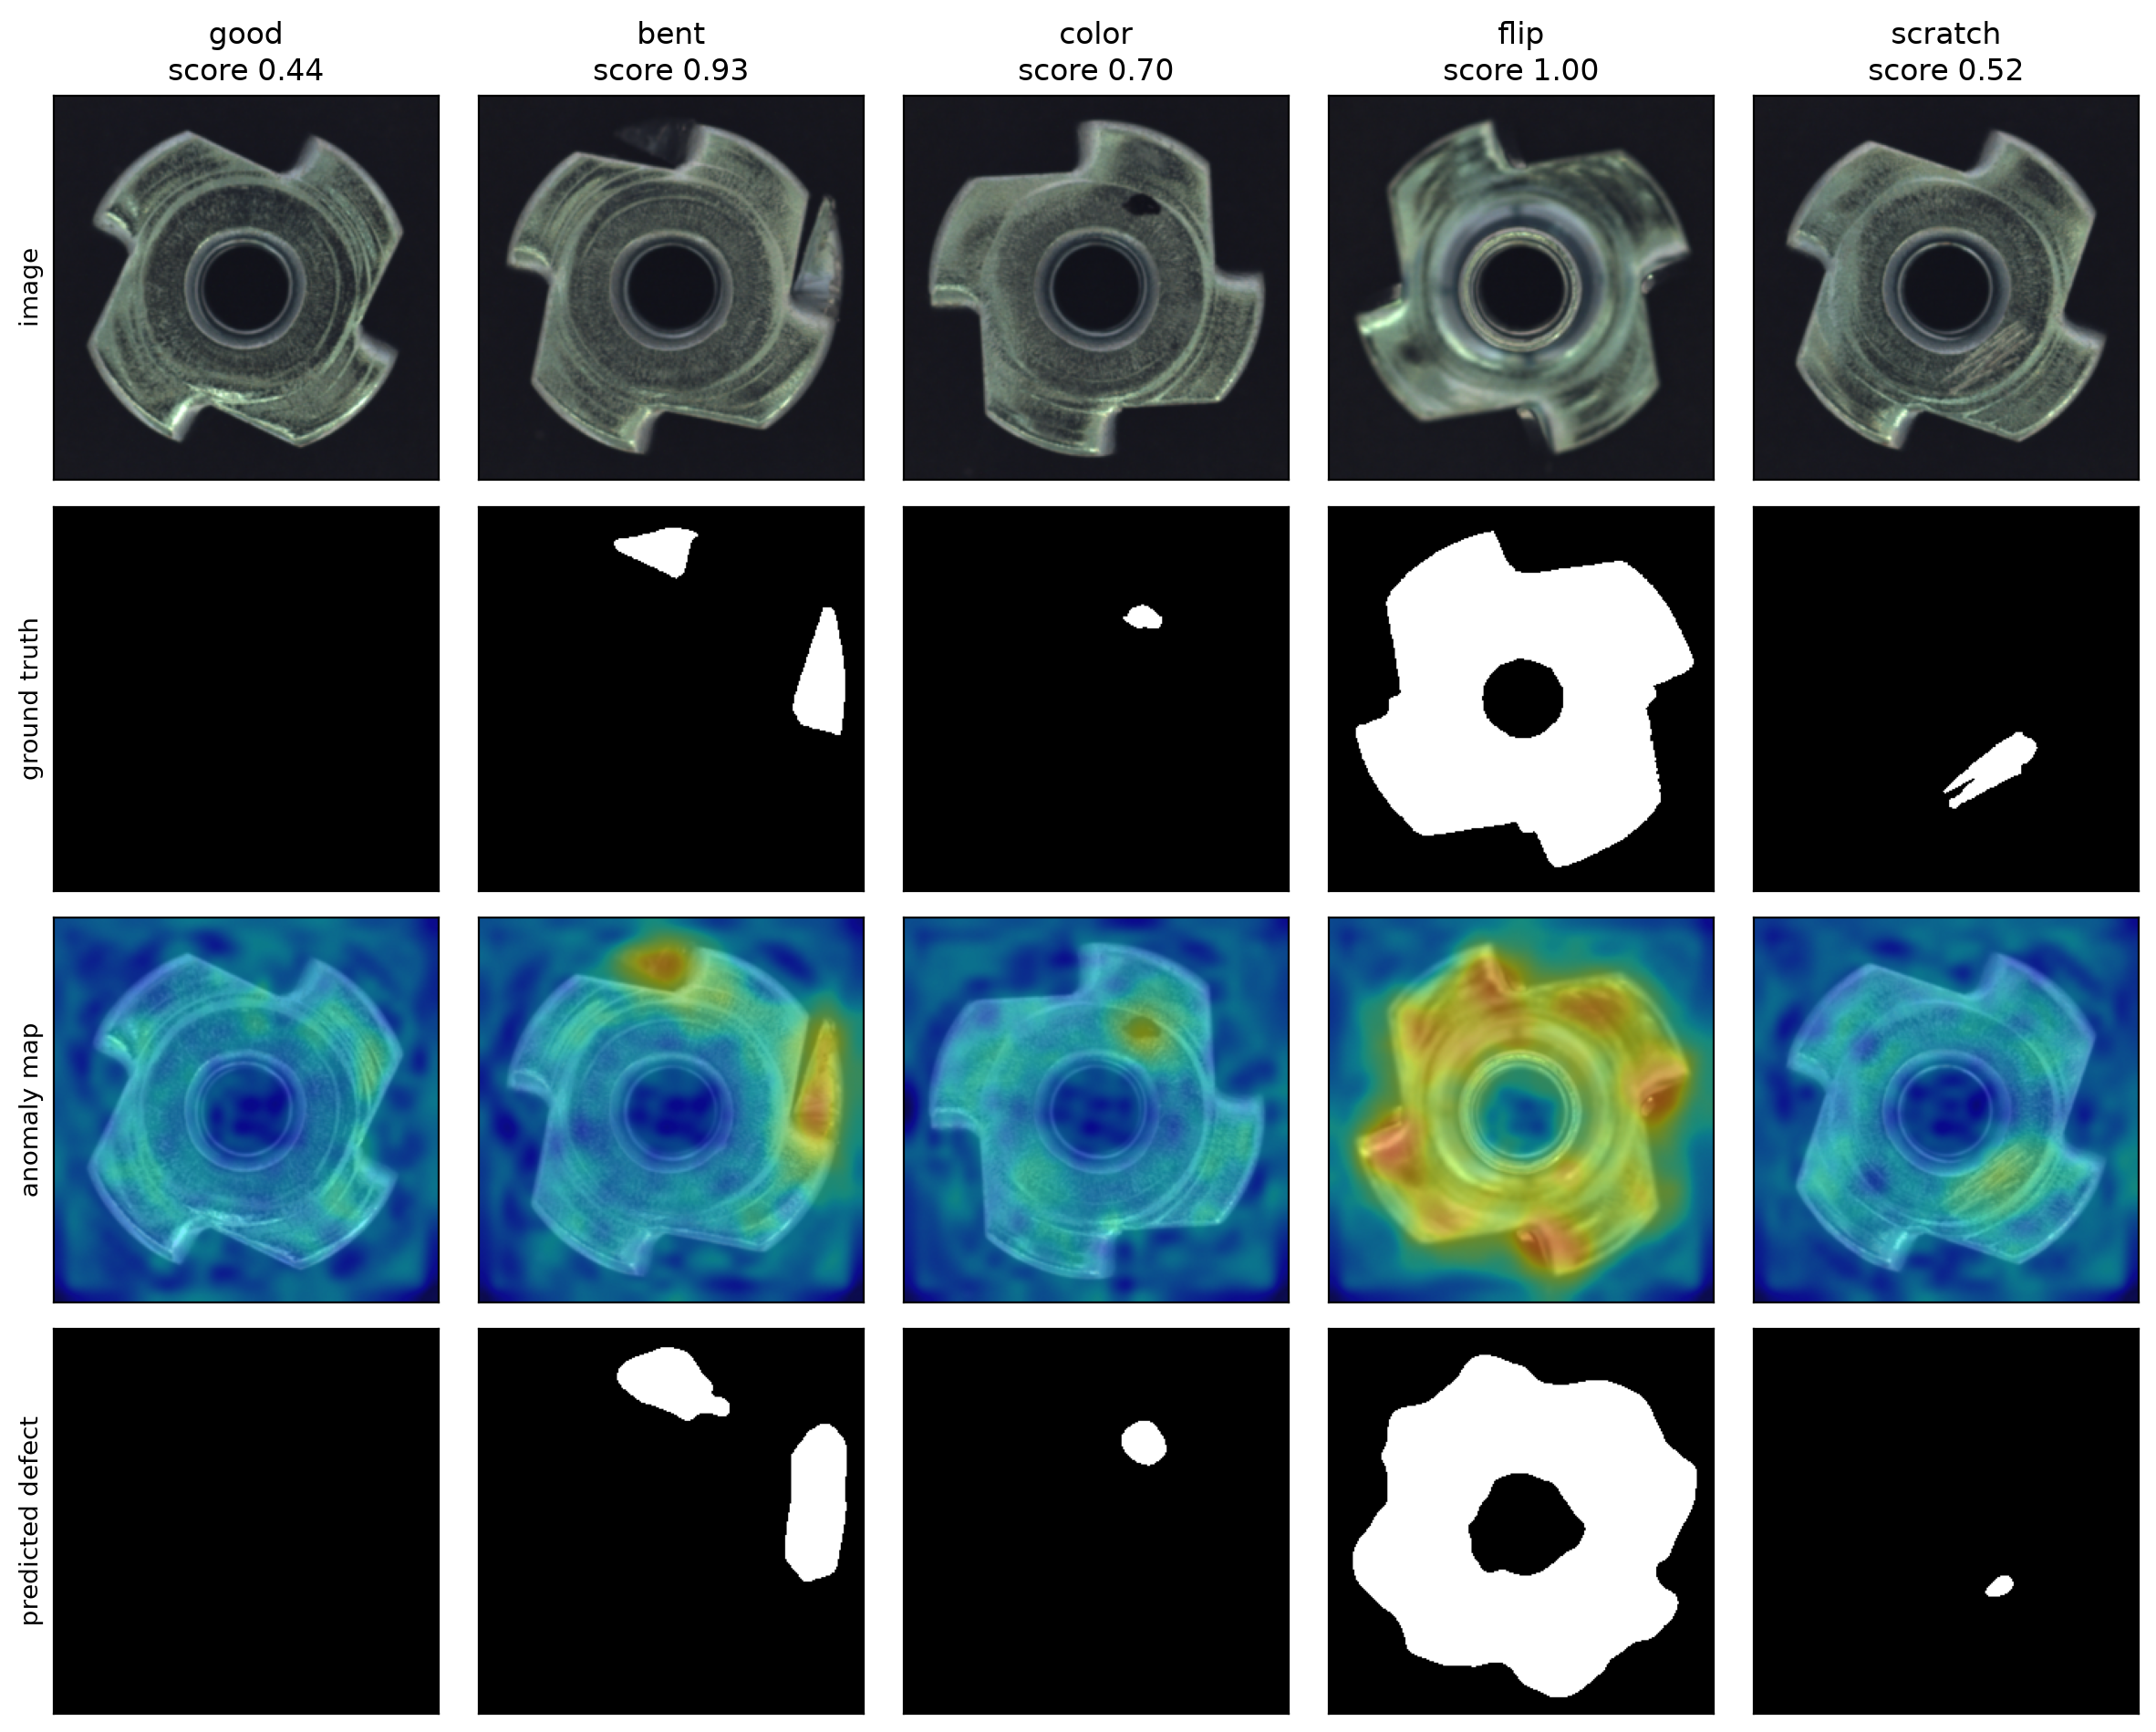

In [7]:
# For each defect type: the image, its ground truth mask, the anomaly map, and the predicted defect pixels.
images = np.concatenate([batch.image.cpu().numpy() for batch in batches])
gt_masks = np.concatenate([batch.gt_mask.cpu().numpy() for batch in batches])
anomaly_maps = np.concatenate([batch.anomaly_map.cpu().numpy() for batch in batches])
pred_masks = np.concatenate([batch.pred_mask.cpu().numpy() for batch in batches])

# The images are normalized for the CNN; undo that to plot them.
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
images = np.clip(images.transpose(0, 2, 3, 1) * std + mean, 0, 1)

rows = ['image', 'ground truth', 'anomaly map', 'predicted defect']
fig, axes = plt.subplots(len(rows), len(defects), figsize=(len(defects) * 2.4, len(rows) * 2.4))
for c, defect in enumerate(defects):
    i = np.flatnonzero(predictions['defect'] == defect)[0]
    axes[0, c].imshow(images[i])
    axes[0, c].set_title(f'{defect}\nscore {predictions["score"][i]:.2f}')
    axes[1, c].imshow(gt_masks[i], cmap='gray', vmin=0, vmax=1)
    axes[2, c].imshow(images[i])
    axes[2, c].imshow(anomaly_maps[i], cmap='jet', alpha=0.5, vmin=0, vmax=1)
    axes[3, c].imshow(pred_masks[i], cmap='gray', vmin=0, vmax=1)
for r, label in enumerate(rows):
    axes[r, 0].set_ylabel(label)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()